In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

100%|██████████| 170M/170M [1:01:21<00:00, 46.3kB/s] 


Epoch 1/10, Loss: 1.9008
Epoch 2/10, Loss: 1.7163
Epoch 3/10, Loss: 1.6500
Epoch 4/10, Loss: 1.6011
Epoch 5/10, Loss: 1.5611
Epoch 6/10, Loss: 1.5260
Epoch 7/10, Loss: 1.4967
Epoch 8/10, Loss: 1.4697
Epoch 9/10, Loss: 1.4460
Epoch 10/10, Loss: 1.4250


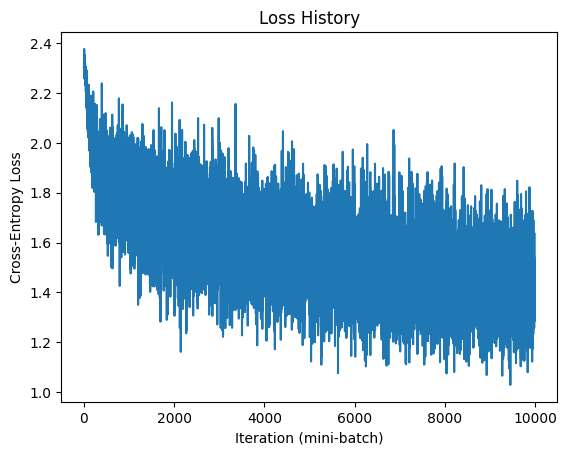

Training accuracy: 52.09%
Test accuracy: 47.68%


In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 1. Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

testset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

classes = (
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
)

# 2. Define network parameters
Din = 3 * 32 * 32  # Input size
H = 100           # Hidden-layer size
K = 10            # Output size

std = 0.01

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

iterations = 10
lr = 0.1
lr_decay = 0.9
reg = 0.0

loss_history = []

# 3. Training loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        y_train_onehot = nn.functional.one_hot(
            labels, K
        ).float()

        z1 = x_train.mm(w1) + b1
        hidden = torch.sigmoid(z1)

        y_pred = hidden.mm(w2) + b2

        log_probs = y_pred - torch.logsumexp(
            y_pred,
            dim=1,
            keepdim=True
        )
        probs = torch.exp(log_probs)

        loss = (
            -(1.0 / Ntr) * torch.sum(y_train_onehot * log_probs)
            + reg * (
                torch.sum(w1**2) + torch.sum(w2**2)
            )
        )

        loss_history.append(loss.item())
        running_loss += loss.item()


        # Derivative of softmax + cross-entropy
        dy_pred = (probs - y_train_onehot) / Ntr

        # Output-layer gradients
        dw2 = hidden.t().mm(dy_pred) + 2.0 * reg * w2
        db2 = dy_pred.sum(dim=0)

        # Gradient through hidden layer
        dhidden = dy_pred.mm(w2.t())

        # Sigmoid derivative
        dz1 = dhidden * hidden * (1.0 - hidden)

        # Input-to-hidden layer gradients
        dw1 = x_train.t().mm(dz1) + 2.0 * reg * w1
        db1 = dz1.sum(dim=0)

        w1 -= lr * dw1
        b1 -= lr * db1

        w2 -= lr * dw2
        b2 -= lr * db2

    # Print mean loss for each epoch
    print(
        f"Epoch {t + 1}/{iterations}, "
        f"Loss: {running_loss / len(trainloader):.4f}"
    )

    # Learning-rate decay
    lr *= lr_decay

# 4. Plotting the loss history
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration (mini-batch)")
plt.ylabel("Cross-Entropy Loss")
plt.show()

# 5. Calculate accuracy on training set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        hidden_train = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = hidden_train.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (
            predicted_train == labels
        ).sum().item()

train_acc = 100.0 * correct_train / total_train

print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate accuracy on test set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        hidden_test = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = hidden_test.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (
            predicted_test == labels
        ).sum().item()

test_acc = 100.0 * correct_test / total_test

print(f"Test accuracy: {test_acc:.2f}%")

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Shared settings for both models
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 64
epochs = 10
learning_rate = 0.001
seed = 42

print(f"Using device: {device}")

# Shared MNIST datasets
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

trainset = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

testset = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

# These loaders evaluate the complete datasets after each epoch.
train_eval_loader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=False, num_workers=0
)

testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=0
)

criterion = nn.CrossEntropyLoss()
results = {}


# Shared evaluation function
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss, correct, total = 0.0, 0, 0
    cm = torch.zeros(10, 10, dtype=torch.long, device=device)

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        # Rows: true labels; columns: predicted labels
        cm += torch.bincount(
            labels * 10 + predictions, minlength=100
        ).reshape(10, 10)

    return total_loss / total, 100.0 * correct / total, cm.cpu()


# Shared training function
def train_and_log(model_class, name):
    torch.manual_seed(seed)

    model = model_class().to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Both models receive the same shuffled batch order.
    generator = torch.Generator().manual_seed(seed)
    trainloader = torch.utils.data.DataLoader(
        trainset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    history = {
        "train_loss": [],
        "test_loss": [],
        "train_acc": [],
        "test_acc": []
    }

    for epoch in range(epochs):
        model.train()

        for inputs, labels in trainloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        # Evaluate the final parameters of this epoch.
        # Dropout is disabled and BN uses stored statistics.
        train_loss, train_acc, _ = evaluate(model, train_eval_loader)
        test_loss, test_acc, cm = evaluate(model, testloader)

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)

        print(
            f"{name} | Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Test loss: {test_loss:.4f} | "
            f"Train accuracy: {train_acc:.2f}% | "
            f"Test accuracy: {test_acc:.2f}%"
        )

    history["confusion_matrix"] = cm
    return model, history


# LeNet-5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),       # 6 x 28 x 28
            nn.Tanh(),
            nn.AvgPool2d(2),                     # 6 x 14 x 14

            nn.Conv2d(6, 16, kernel_size=5),      # 16 x 10 x 10
            nn.Tanh(),
            nn.AvgPool2d(2),                     # 16 x 5 x 5

            nn.Conv2d(16, 120, kernel_size=5),    # 120 x 1 x 1
            nn.Tanh()
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


lenet_model, results["LeNet-5"] = train_and_log(LeNet5, "LeNet-5")

Using device: cpu
LeNet-5 | Epoch 1/10 | Train loss: 0.0804 | Test loss: 0.0787 | Train accuracy: 97.58% | Test accuracy: 97.40%
LeNet-5 | Epoch 2/10 | Train loss: 0.0512 | Test loss: 0.0592 | Train accuracy: 98.40% | Test accuracy: 98.11%
LeNet-5 | Epoch 3/10 | Train loss: 0.0356 | Test loss: 0.0502 | Train accuracy: 98.89% | Test accuracy: 98.44%
LeNet-5 | Epoch 4/10 | Train loss: 0.0304 | Test loss: 0.0494 | Train accuracy: 99.07% | Test accuracy: 98.47%
LeNet-5 | Epoch 5/10 | Train loss: 0.0214 | Test loss: 0.0431 | Train accuracy: 99.35% | Test accuracy: 98.67%
LeNet-5 | Epoch 6/10 | Train loss: 0.0199 | Test loss: 0.0415 | Train accuracy: 99.36% | Test accuracy: 98.76%
LeNet-5 | Epoch 7/10 | Train loss: 0.0183 | Test loss: 0.0431 | Train accuracy: 99.42% | Test accuracy: 98.75%
LeNet-5 | Epoch 8/10 | Train loss: 0.0148 | Test loss: 0.0440 | Train accuracy: 99.53% | Test accuracy: 98.87%
LeNet-5 | Epoch 9/10 | Train loss: 0.0165 | Test loss: 0.0466 | Train accuracy: 99.45% | Test 

In [6]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Convolutional layer 1
            nn.Conv2d(1, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),                     # 16 x 16 x 16

            # Convolutional layer 2
            nn.Conv2d(16, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                     # 32 x 8 x 8

            # Convolutional layer 3
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)                      # 64 x 4 x 4
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn_model, results["Small CNN"] = train_and_log(SmallCNN, "Small CNN")

Small CNN | Epoch 1/10 | Train loss: 0.0623 | Test loss: 0.0590 | Train accuracy: 98.11% | Test accuracy: 98.18%
Small CNN | Epoch 2/10 | Train loss: 0.0392 | Test loss: 0.0378 | Train accuracy: 98.83% | Test accuracy: 98.80%
Small CNN | Epoch 3/10 | Train loss: 0.0291 | Test loss: 0.0334 | Train accuracy: 99.14% | Test accuracy: 98.95%
Small CNN | Epoch 4/10 | Train loss: 0.0299 | Test loss: 0.0328 | Train accuracy: 99.06% | Test accuracy: 98.98%
Small CNN | Epoch 5/10 | Train loss: 0.0238 | Test loss: 0.0333 | Train accuracy: 99.29% | Test accuracy: 98.98%
Small CNN | Epoch 6/10 | Train loss: 0.0229 | Test loss: 0.0381 | Train accuracy: 99.30% | Test accuracy: 99.01%
Small CNN | Epoch 7/10 | Train loss: 0.0159 | Test loss: 0.0259 | Train accuracy: 99.52% | Test accuracy: 99.27%
Small CNN | Epoch 8/10 | Train loss: 0.0129 | Test loss: 0.0227 | Train accuracy: 99.60% | Test accuracy: 99.40%
Small CNN | Epoch 9/10 | Train loss: 0.0126 | Test loss: 0.0253 | Train accuracy: 99.64% | Test 


Results after 10 epochs
Model           Training accuracy    Test accuracy
LeNet-5                    99.75%           98.68%
Small CNN                  99.72%           99.25%


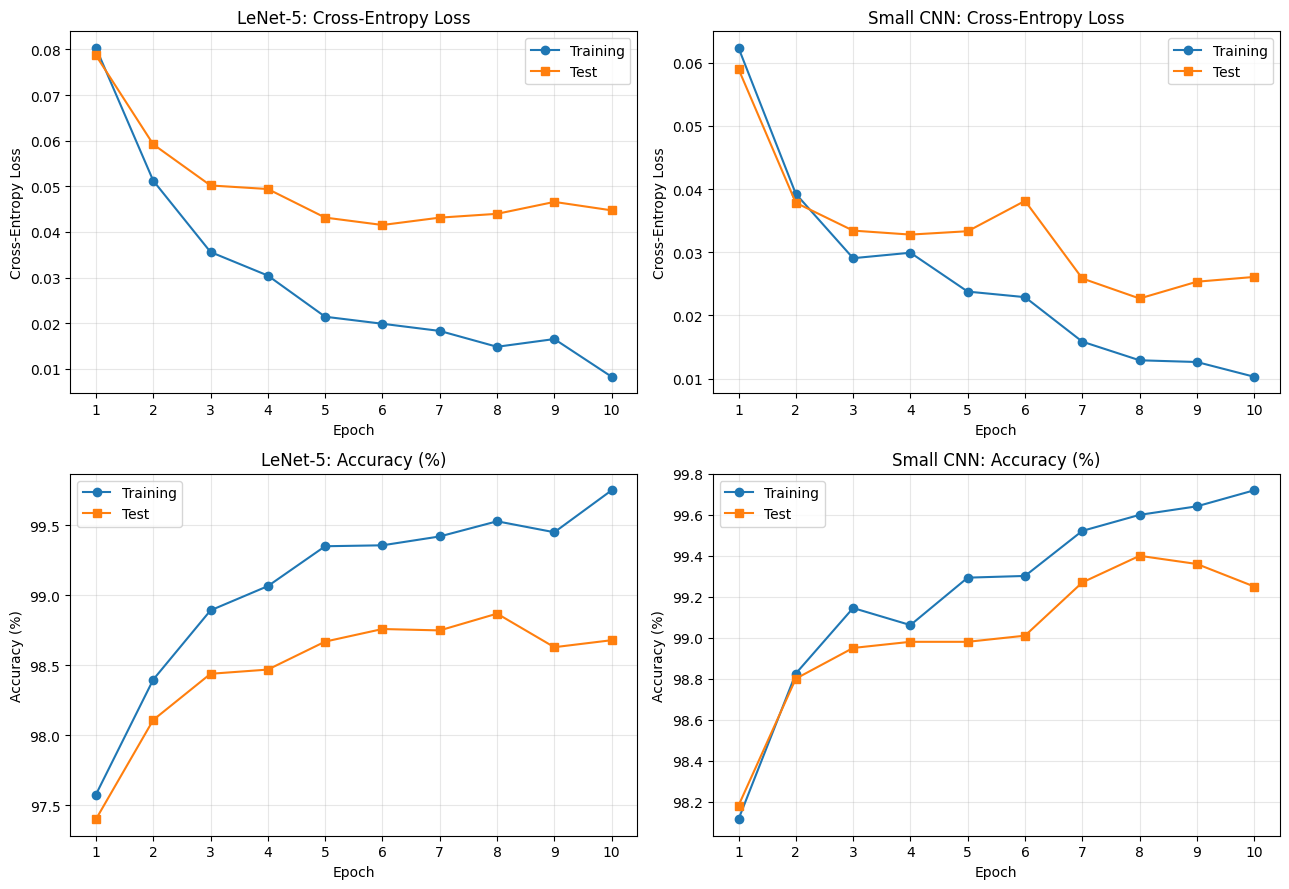


LeNet-5 test confusion matrix:
Rows = true labels; columns = predicted labels
[[ 971    0    0    0    0    0    2    0    5    2]
 [   0 1130    1    0    0    0    2    1    1    0]
 [   2    0 1021    2    1    0    2    2    2    0]
 [   0    0    1 1001    0    2    0    1    4    1]
 [   0    0    1    0  971    0    5    1    1    3]
 [   2    0    0    9    0  876    3    0    0    2]
 [   4    2    1    1    1    1  943    0    5    0]
 [   1    2    7    1    2    0    0 1011    0    4]
 [   0    0    2    2    2    0    0    1  964    3]
 [   0    0    0    4   15    1    0    3    6  980]]

Small CNN test confusion matrix:
Rows = true labels; columns = predicted labels
[[ 978    0    0    0    0    0    1    1    0    0]
 [   0 1129    1    2    0    0    1    1    1    0]
 [   1    0 1030    0    1    0    0    0    0    0]
 [   0    0    0 1004    0    3    0    2    1    0]
 [   0    0    1    0  978    0    1    0    1    1]
 [   1    0    0    5    0  882    2    1   

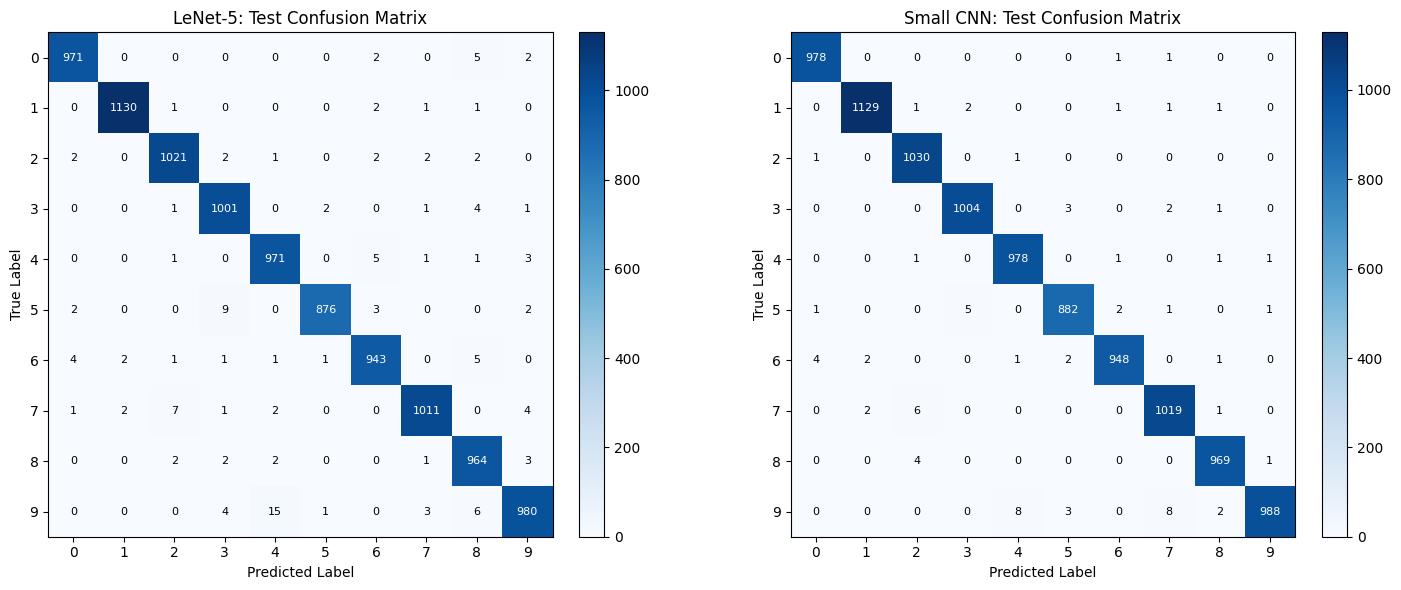

In [8]:
# Display final accuracies
print(f"\nResults after {epochs} epochs")
print(f"{'Model':<12} {'Training accuracy':>20} {'Test accuracy':>16}")

for name, history in results.items():
    print(
        f"{name:<12} "
        f"{history['train_acc'][-1]:>19.2f}% "
        f"{history['test_acc'][-1]:>15.2f}%"
    )

# Plot per-epoch loss and accuracy for both models
epoch_numbers = range(1, epochs + 1)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for column, (name, history) in enumerate(results.items()):
    for row, metric, ylabel in [
        (0, "loss", "Cross-Entropy Loss"),
        (1, "acc", "Accuracy (%)")
    ]:
        ax = axes[row, column]

        ax.plot(
            epoch_numbers, history[f"train_{metric}"],
            marker="o", label="Training"
        )
        ax.plot(
            epoch_numbers, history[f"test_{metric}"],
            marker="s", label="Test"
        )

        ax.set_title(f"{name}: {ylabel}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.set_xticks(list(epoch_numbers))
        ax.grid(alpha=0.3)
        ax.legend()

plt.tight_layout()
plt.show()

# Display final test confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (name, history) in zip(axes, results.items()):
    cm = history["confusion_matrix"].numpy()

    print(f"\n{name} test confusion matrix:")
    print("Rows = true labels; columns = predicted labels")
    print(cm)

    image = ax.imshow(cm, cmap="Blues")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

    ax.set_title(f"{name}: Test Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

    for i in range(10):
        for j in range(10):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black"
            )

plt.tight_layout()
plt.show()

# **Question 3**

In [9]:
from pathlib import Path
from copy import deepcopy
import urllib.request
import zipfile
import time

tl_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tl_epochs = 25
tl_batch_size = 4

data_root = Path("./data")
data_root.mkdir(exist_ok=True)

tl_data_dir = data_root / "hymenoptera_data"

if not tl_data_dir.exists():
    archive = data_root / "hymenoptera_data.zip"
    urllib.request.urlretrieve(
        "https://download.pytorch.org/tutorial/hymenoptera_data.zip",
        archive
    )
    with zipfile.ZipFile(archive) as file:
        file.extractall(data_root)

tl_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

tl_datasets = {
    phase: torchvision.datasets.ImageFolder(
        tl_data_dir / phase,
        transform=tl_transforms[phase]
    )
    for phase in ["train", "val"]
}

tl_classes = tl_datasets["train"].classes
assert tl_classes == tl_datasets["val"].classes
print("Classes:", tl_classes)

tl_criterion = nn.CrossEntropyLoss()


def run_transfer(name, freeze_backbone=False):
    torch.manual_seed(42)

    model = torchvision.models.resnet18(
        weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1
    )

    if freeze_backbone:
        for parameter in model.parameters():
            parameter.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, len(tl_classes))
    model = model.to(tl_device)

    trainable_parameters = [
        parameter for parameter in model.parameters()
        if parameter.requires_grad
    ]

    optimizer = optim.SGD(
        trainable_parameters,
        lr=0.001,
        momentum=0.9
    )

    scheduler = optim.lr_scheduler.StepLR(
        optimizer, step_size=7, gamma=0.1
    )

    generator = torch.Generator().manual_seed(42)

    loaders = {
        phase: torch.utils.data.DataLoader(
            tl_datasets[phase],
            batch_size=tl_batch_size,
            shuffle=(phase == "train"),
            num_workers=0,
            generator=generator if phase == "train" else None
        )
        for phase in ["train", "val"]
    }

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_accuracy = -1.0
    best_epoch = 0
    best_loss = float("inf")
    best_weights = None
    start = time.perf_counter()

    for epoch in range(tl_epochs):
        for phase in ["train", "val"]:
            is_training = phase == "train"

            if is_training and not freeze_backbone:
                model.train()
            else:
                model.eval()

                # Keep the frozen backbone, including batch
                # normalization statistics, fixed.
                if is_training:
                    model.fc.train()

            running_loss = 0.0
            correct = 0
            total = 0

            for inputs, labels in loaders[phase]:
                inputs = inputs.to(tl_device)
                labels = labels.to(tl_device)

                if is_training:
                    optimizer.zero_grad()

                with torch.set_grad_enabled(is_training):
                    outputs = model(inputs)
                    loss = tl_criterion(outputs, labels)

                    if is_training:
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * labels.size(0)
                correct += (
                    outputs.argmax(dim=1) == labels
                ).sum().item()
                total += labels.size(0)

            epoch_loss = running_loss / total
            epoch_accuracy = 100.0 * correct / total

            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_accuracy)

            if phase == "val" and epoch_accuracy > best_accuracy:
                best_accuracy = epoch_accuracy
                best_loss = epoch_loss
                best_epoch = epoch + 1
                best_weights = deepcopy(model.state_dict())

        scheduler.step()

        print(
            f"{name} | Epoch {epoch + 1}/{tl_epochs} | "
            f"Train loss: {history['train_loss'][-1]:.4f} | "
            f"Train acc: {history['train_acc'][-1]:.2f}% | "
            f"Val loss: {history['val_loss'][-1]:.4f} | "
            f"Val acc: {history['val_acc'][-1]:.2f}%"
        )

    elapsed = time.perf_counter() - start

    model.load_state_dict(best_weights)
    model.eval()

    summary = {
        "best_epoch": best_epoch,
        "val_loss": best_loss,
        "val_accuracy": best_accuracy,
        "trainable_parameters": sum(
            parameter.numel() for parameter in trainable_parameters
        ),
        "time_minutes": elapsed / 60
    }

    return model, history, summary

Classes: ['ants', 'bees']


In [10]:
finetuned_model, finetune_history, finetune_results = run_transfer(
    "Fine-tuning",
    freeze_backbone=False
)

print(
    f"\nBest validation accuracy: "
    f"{finetune_results['val_accuracy']:.2f}%"
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 304MB/s]


Fine-tuning | Epoch 1/25 | Train loss: 0.6538 | Train acc: 65.16% | Val loss: 0.2691 | Val acc: 89.54%
Fine-tuning | Epoch 2/25 | Train loss: 0.5566 | Train acc: 77.46% | Val loss: 0.6277 | Val acc: 76.47%
Fine-tuning | Epoch 3/25 | Train loss: 0.5237 | Train acc: 77.46% | Val loss: 0.2214 | Val acc: 92.81%
Fine-tuning | Epoch 4/25 | Train loss: 0.4381 | Train acc: 80.74% | Val loss: 0.2390 | Val acc: 88.89%
Fine-tuning | Epoch 5/25 | Train loss: 0.4682 | Train acc: 79.51% | Val loss: 0.2749 | Val acc: 91.50%
Fine-tuning | Epoch 6/25 | Train loss: 0.5083 | Train acc: 81.15% | Val loss: 0.4604 | Val acc: 85.62%
Fine-tuning | Epoch 7/25 | Train loss: 0.5813 | Train acc: 80.74% | Val loss: 0.4969 | Val acc: 84.97%
Fine-tuning | Epoch 8/25 | Train loss: 0.6638 | Train acc: 75.82% | Val loss: 0.3230 | Val acc: 88.24%
Fine-tuning | Epoch 9/25 | Train loss: 0.4452 | Train acc: 81.97% | Val loss: 0.2573 | Val acc: 89.54%
Fine-tuning | Epoch 10/25 | Train loss: 0.3081 | Train acc: 85.25% | Val 